# Mini-opdracht Les 1 – Dimensionality Reduction op leesmateriaal

In dit notebook pas ik drie technieken voor dimensionality reduction toe op de opgeschoonde leescatalogus
(`leesmateriaal_opgeschoond.csv`, gemaakt in `08_Cleaning_Leesmateriaal.ipynb`):

1. **PCA** (Principal Component Analysis)
2. **t-SNE** (t-Distributed Stochastic Neighbor Embedding)
3. **UMAP** (Uniform Manifold Approximation and Projection)

Daarna vergelijk ik de visualisaties, experimenteer ik met de parameters en trek ik een conclusie.

## Stap 1 – Dataset kiezen en voorbereiden
De dataset bevat per leesmateriaal een aantal **numerieke features** over lengte en leesbaarheid.
Deze gebruik ik als input:

| Feature | Betekenis |
|---|---|
| `Aantal_paginas` | lengte van het materiaal |
| `Geschatte_leestijd_min` | geschatte leestijd in minuten |
| `Woordenaantal_omschrijving` | aantal woorden in de korte omschrijving |
| `Gem_woordlengte` | gemiddelde woordlengte |
| `Gem_zinslengte_woorden` | gemiddelde zinslengte |
| `Aandeel_lange_woorden_pct` | percentage lange woorden |
| `Aantal_zinnen` | aantal zinnen in de omschrijving |
| `Leescomplexiteit_score` | score voor leescomplexiteit |

`Publicatiejaar` en `Gemiddelde_beoordeling` laat ik weg: die zeggen niets over de inhoud/leesbaarheid
en `Gemiddelde_beoordeling` mist in ruim een derde van de rijen.

Als **labels** (alleen voor de kleur in de grafieken, niet als input) gebruik ik `Type_materiaal` en `Niveau`.

In [1]:
# Uncomment als umap nog niet geïnstalleerd is
# %pip install umap-learn

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap
import warnings

# UMAP waarschuwt dat random_state parallel rekenen uitzet; dat is hier geen probleem
warnings.filterwarnings("ignore", message="n_jobs value")

df = pd.read_csv("../datasets/leesmateriaal_opgeschoond.csv")
print("Shape:", df.shape)

features = [
    "Aantal_paginas",
    "Geschatte_leestijd_min",
    "Woordenaantal_omschrijving",
    "Gem_woordlengte",
    "Gem_zinslengte_woorden",
    "Aandeel_lange_woorden_pct",
    "Aantal_zinnen",
    "Leescomplexiteit_score",
]

df[features].describe().T

Shape: (283, 30)


,count,mean,std,min,25%,50%,75%,max
Aantal_paginas,255.0,184.996078,112.073215,1.00,118.50,185.00,265.500,400.0
Geschatte_leestijd_min,274.0,377.343066,263.985609,5.00,171.00,366.00,587.500,946.0
Woordenaantal_omschrijving,283.0,14.844523,7.469360,1.00,5.00,17.00,20.000,32.0
Gem_woordlengte,283.0,7.217244,3.972142,4.33,5.73,6.35,7.595,54.0
Gem_zinslengte_woorden,265.0,8.230189,3.884682,1.00,4.00,9.00,10.000,26.0
Aandeel_lange_woorden_pct,283.0,42.430035,21.840599,0.00,28.60,35.00,50.000,100.0
Aantal_zinnen,283.0,1.689046,0.463704,1.00,1.00,2.00,2.000,2.0
Leescomplexiteit_score,277.0,45.813718,12.202466,14.90,36.60,45.40,52.200,80.2


In [2]:
# Ontbrekende waarden per feature
df[features].isna().sum()

Aantal_paginas                28
Geschatte_leestijd_min         9
Woordenaantal_omschrijving     0
Gem_woordlengte                0
Gem_zinslengte_woorden        18
Aandeel_lange_woorden_pct      0
Aantal_zinnen                  0
Leescomplexiteit_score         6
dtype: int64

Er zijn enkele ontbrekende waarden. PCA, t-SNE en UMAP kunnen daar niet mee omgaan,
dus ik vul ze aan met de **mediaan** van de kolom (minder gevoelig voor uitschieters dan het gemiddelde).
Daarna **schaal** ik de data met `StandardScaler`, zodat bijvoorbeeld leestijd (honderden minuten)
niet zwaarder telt dan woordlengte (± 7).

In [3]:
# 1. Ontbrekende waarden aanvullen met de mediaan
X = df[features].fillna(df[features].median())

# 2. Labels voor de kleuren (onbekend als er geen waarde is)
type_materiaal = df["Type_materiaal"].fillna("onbekend")
niveau = df["Niveau"].fillna("onbekend")

# 3. Schalen
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("X_scaled shape:", X_scaled.shape)

X_scaled shape: (283, 8)


In [4]:
# Hulpfunctie: scatterplot met een kleur per categorie en een legenda
def plot_projectie(ax, X_2d, labels, titel, cmap="tab10"):
    categorieen = sorted(labels.unique())
    kleuren = plt.get_cmap(cmap)
    for i, categorie in enumerate(categorieen):
        masker = (labels == categorie).values
        ax.scatter(X_2d[masker, 0], X_2d[masker, 1], s=18, alpha=0.8,
                   color=kleuren(i), label=f"{categorie} ({masker.sum()})")
    ax.set_title(titel)
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")
    ax.legend(fontsize=7, loc="best")

## Stap 2 – Drie technieken uitvoeren

### 2.1 PCA
PCA zoekt de richtingen (componenten) met de meeste variantie in de data en projecteert de data daarop.

Verklaarde variantie per component: [0.514 0.184]
Totaal behouden variantie: 0.698
Rekentijd: 0.000 s


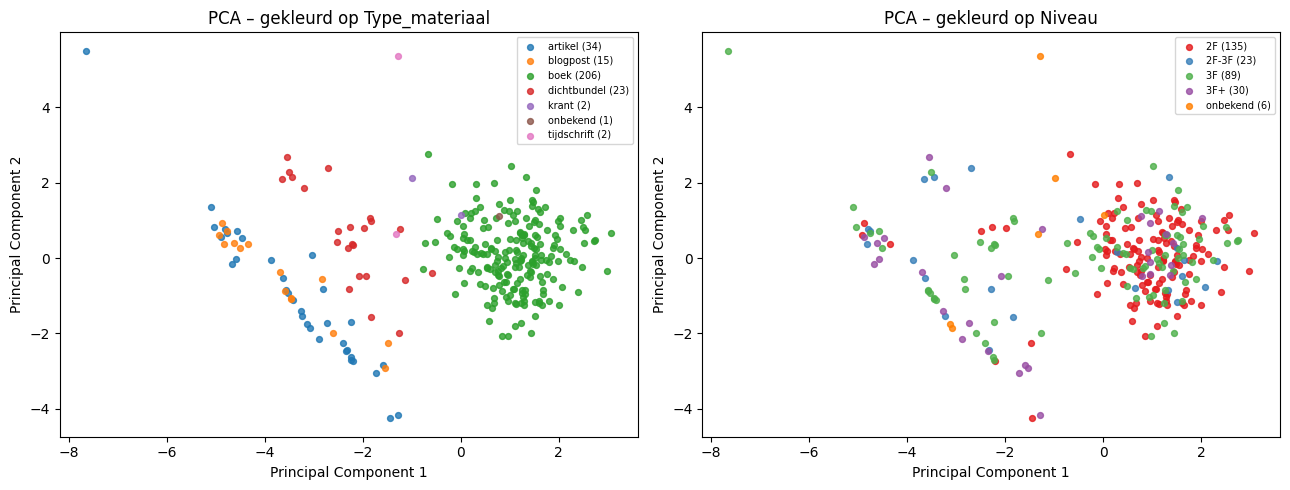

In [5]:
# PCA uitvoeren en terugbrengen naar 2 dimensies
start = time.time()
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
tijd_pca = time.time() - start

print("Verklaarde variantie per component:", pca.explained_variance_ratio_.round(3))
print("Totaal behouden variantie:", round(pca.explained_variance_ratio_.sum(), 3))
print(f"Rekentijd: {tijd_pca:.3f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_projectie(axes[0], X_pca, type_materiaal, "PCA – gekleurd op Type_materiaal")
plot_projectie(axes[1], X_pca, niveau, "PCA – gekleurd op Niveau", cmap="Set1")
for ax in axes:
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

Welke features bepalen de twee componenten? Dat is te zien aan de *loadings* (gewichten per feature):

In [6]:
loadings = pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"])
loadings.round(2).sort_values("PC1")

,PC1,PC2
Aandeel_lange_woorden_pct,-0.41,0.34
Leescomplexiteit_score,-0.30,0.56
Gem_woordlengte,-0.24,0.43
Geschatte_leestijd_min,0.29,0.38
Aantal_paginas,0.32,0.39
Gem_zinslengte_woorden,0.36,0.25
Aantal_zinnen,0.41,0.03
Woordenaantal_omschrijving,0.44,0.16


### 2.2 t-SNE
t-SNE probeert lokale structuren te behouden: punten die dicht bij elkaar liggen in de originele ruimte,
blijven ook dicht bij elkaar in 2D.

Rekentijd: 0.556 s


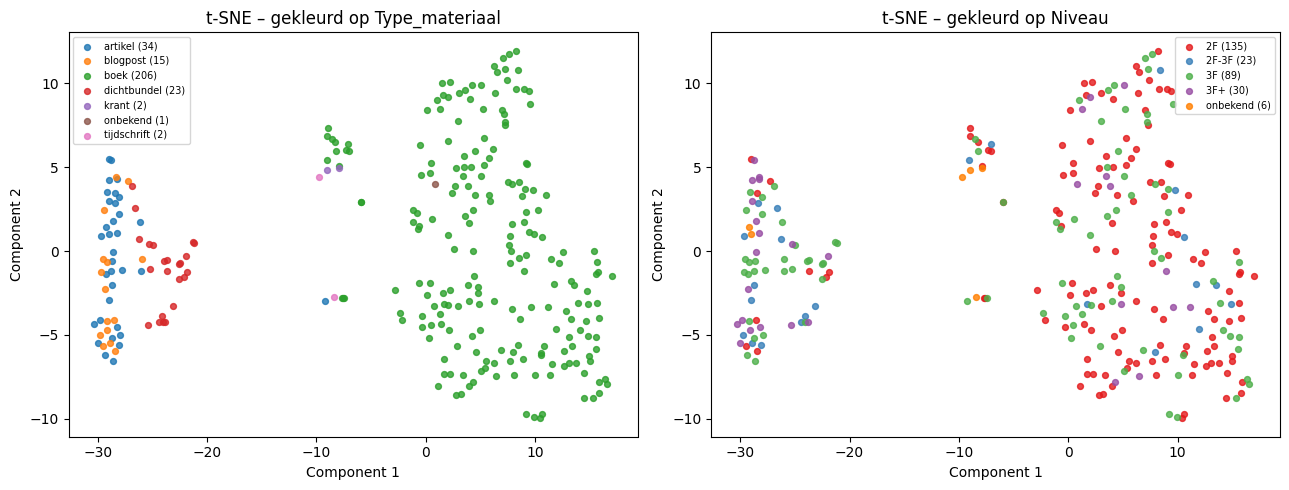

In [7]:
start = time.time()
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)
tijd_tsne = time.time() - start
print(f"Rekentijd: {tijd_tsne:.3f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_projectie(axes[0], X_tsne, type_materiaal, "t-SNE – gekleurd op Type_materiaal")
plot_projectie(axes[1], X_tsne, niveau, "t-SNE – gekleurd op Niveau", cmap="Set1")
plt.tight_layout()
plt.show()

### 2.3 UMAP
UMAP is meestal sneller dan t-SNE en behoudt zowel lokale als (deels) globale structuur.

Rekentijd: 7.724 s


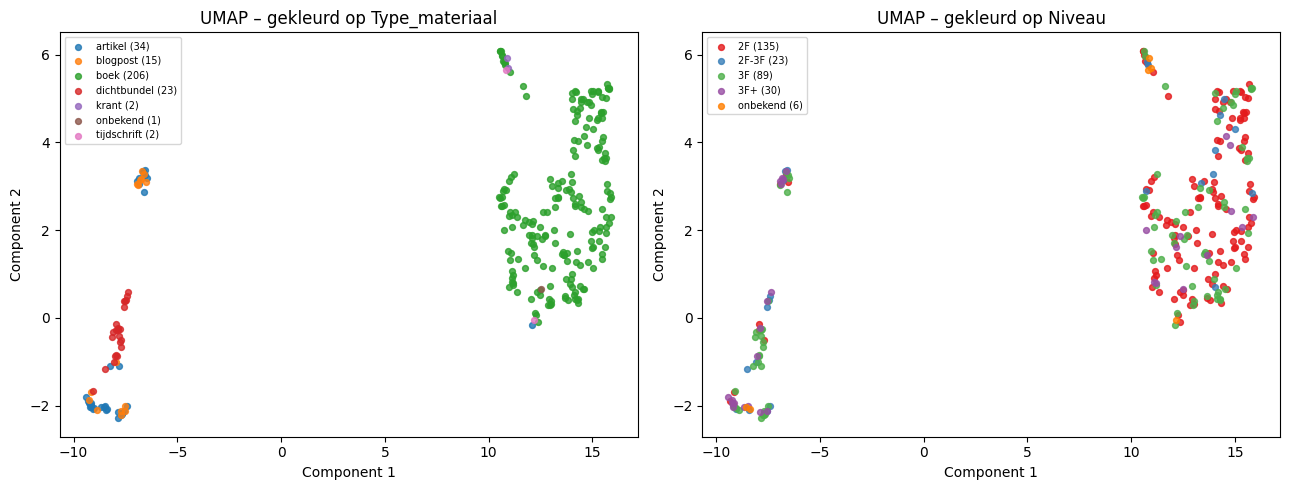

In [8]:
start = time.time()
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = umap_model.fit_transform(X_scaled)
tijd_umap = time.time() - start
print(f"Rekentijd: {tijd_umap:.3f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_projectie(axes[0], X_umap, type_materiaal, "UMAP – gekleurd op Type_materiaal")
plot_projectie(axes[1], X_umap, niveau, "UMAP – gekleurd op Niveau", cmap="Set1")
plt.tight_layout()
plt.show()

*Let op: de eerste keer UMAP draaien duurt langer, omdat `numba` de code dan nog compileert.*

## Stap 3 – Visualiseren en vergelijken
De drie projecties naast elkaar, op dezelfde (geschaalde) data:

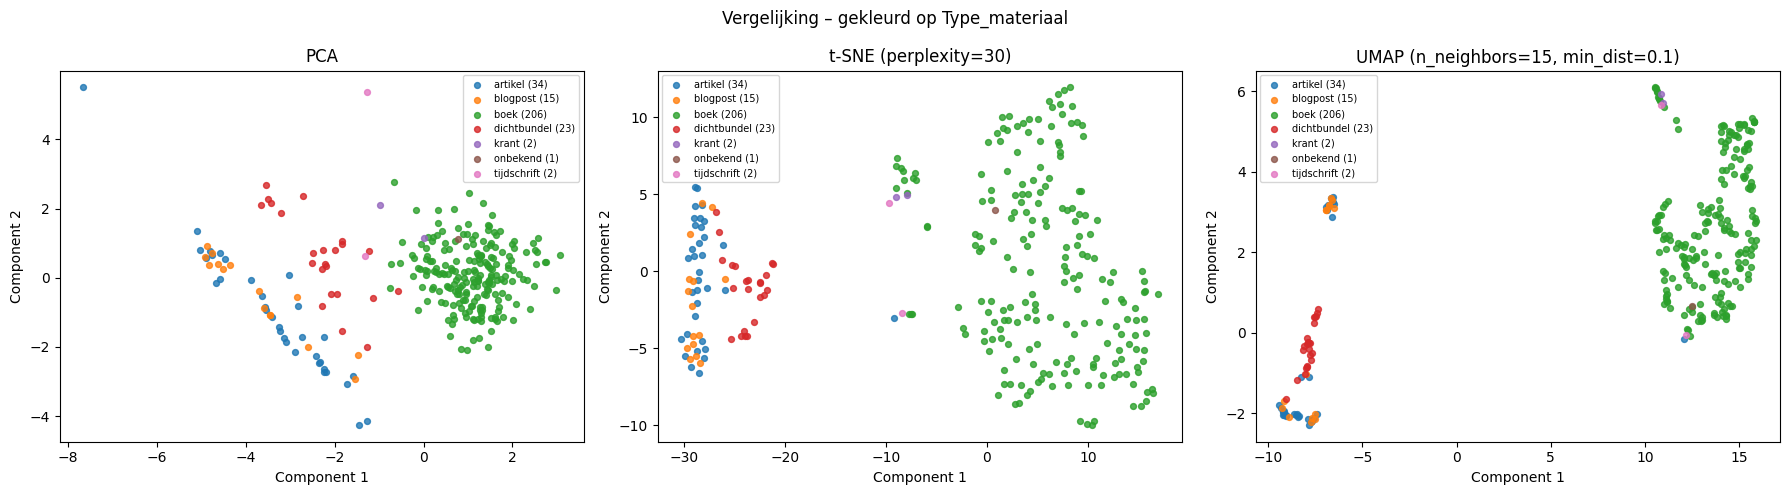

  techniek  rekentijd (s)
0      PCA          0.000
1    t-SNE          0.556
2     UMAP          7.724


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_projectie(axes[0], X_pca, type_materiaal, "PCA")
plot_projectie(axes[1], X_tsne, type_materiaal, "t-SNE (perplexity=30)")
plot_projectie(axes[2], X_umap, type_materiaal, "UMAP (n_neighbors=15, min_dist=0.1)")
plt.suptitle("Vergelijking – gekleurd op Type_materiaal")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"techniek": ["PCA", "t-SNE", "UMAP"],
                    "rekentijd (s)": [round(tijd_pca, 3), round(tijd_tsne, 3), round(tijd_umap, 3)]}))

### Interpretatie

**1. Hoe verschillen de visualisaties van elkaar?**
- **PCA** geeft één doorlopende wolk. Rechts ligt een grote, compacte groep boeken; links liggen artikelen, blogposts en dichtbundels, die als een uitgerekte "staart" in elkaar overlopen. De afstanden in de grafiek zijn echt betekenisvol: PC1 loopt van korte, complexe teksten (veel lange woorden, hoge leescomplexiteit, links) naar lange materialen met langere omschrijvingen (meer pagina's, leestijd en zinnen, rechts).
- **t-SNE** trekt de data uit elkaar in duidelijk gescheiden groepen: een grote groep boeken, een klein groepje boeken/kranten/tijdschriften, en links een groep met artikelen, blogposts en dichtbundels. Binnen die linkergroep vormen de dichtbundels een eigen sub-cluster.
- **UMAP** maakt de scherpste en meest compacte clusters: de boeken liggen ver weg van de rest, en artikelen/blogposts en dichtbundels vormen elk strakke "slierten". De ruimte tussen de clusters is groot en leeg.

**2. Welke techniek laat de clusters het duidelijkst zien?**
UMAP, met t-SNE op een goede tweede plaats. Bij beide is direct zichtbaar dat **boeken** een heel andere "vorm" hebben (lang, veel pagina's) dan **korte teksten** (artikel, blogpost). Ook de **dichtbundels** worden apart gezet. Artikelen en blogposts liggen bij alle drie de technieken door elkaar: op basis van deze features lijken ze gewoon erg op elkaar.

Gekleurd op **Niveau** (2F / 3F / 3F+) is er bij geen van de technieken een duidelijke scheiding. Het taalniveau is dus niet goed af te leiden uit deze lengte- en leesbaarheidsfeatures; alleen 3F+ zit iets vaker bij de korte, complexe teksten.

**3. Hoe interpreteer ik het verschil tussen PCA en t-SNE / UMAP?**
PCA is een **lineaire** techniek: het draait en projecteert de data zó dat zoveel mogelijk variantie behouden blijft (hier 69,8% met 2 componenten). Daardoor blijven globale afstanden kloppen en zijn de assen uit te leggen met de loadings, maar groepen die niet langs een rechte lijn verschillen, overlappen.
t-SNE en UMAP zijn **niet-lineair** en kijken vooral naar *buren*: punten die in de 8-dimensionale ruimte dicht bij elkaar liggen, blijven bij elkaar. Dat geeft mooiere clusters, maar de assen hebben geen betekenis en de afstand *tussen* clusters (en de grootte van een cluster) moet je niet letterlijk nemen.

**4. Welke techniek zou ik kiezen voor de eindopdracht?**
Zie de conclusie onderaan: **UMAP** voor het verkennen van groepen, met PCA als uitlegbare controle.

## Stap 4 – Experimenteren

### 4.1 PCA – aantal componenten en behouden variantie

Verklaarde variantie per component: [0.514 0.184 0.1   0.084 0.06  0.046 0.007 0.004]
Cumulatief: [0.514 0.698 0.799 0.883 0.943 0.989 0.996 1.   ]


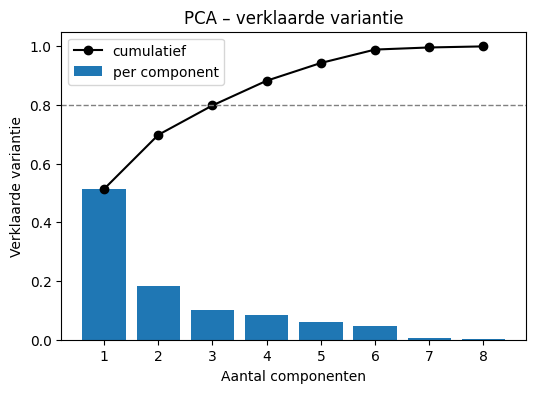

In [10]:
pca_volledig = PCA(n_components=len(features))
pca_volledig.fit(X_scaled)

print("Verklaarde variantie per component:", pca_volledig.explained_variance_ratio_.round(3))
cumulatief = np.cumsum(pca_volledig.explained_variance_ratio_)
print("Cumulatief:", cumulatief.round(3))

plt.figure(figsize=(6, 4))
plt.bar(range(1, len(features) + 1), pca_volledig.explained_variance_ratio_, label="per component")
plt.plot(range(1, len(features) + 1), cumulatief, marker="o", color="black", label="cumulatief")
plt.axhline(0.8, color="grey", linestyle="--", linewidth=1)
plt.xlabel("Aantal componenten")
plt.ylabel("Verklaarde variantie")
plt.title("PCA – verklaarde variantie")
plt.legend()
plt.show()

**Wat valt op bij PCA?**
- PC1 verklaart al **51,4%** en PC2 **18,4%** van de variantie; samen **69,8%**. De 2D-plot laat dus ruim twee derde van de informatie zien.
- Voor **80%** zijn 3 componenten nodig (79,9%), voor 90% ongeveer 5.
- De laatste twee componenten voegen bijna niets toe (< 1%). Dat komt doordat sommige features sterk samenhangen, bijvoorbeeld `Aantal_paginas` en `Geschatte_leestijd_min`.
- PCA is veruit het snelst (enkele milliseconden).

### 4.2 t-SNE – perplexity aanpassen

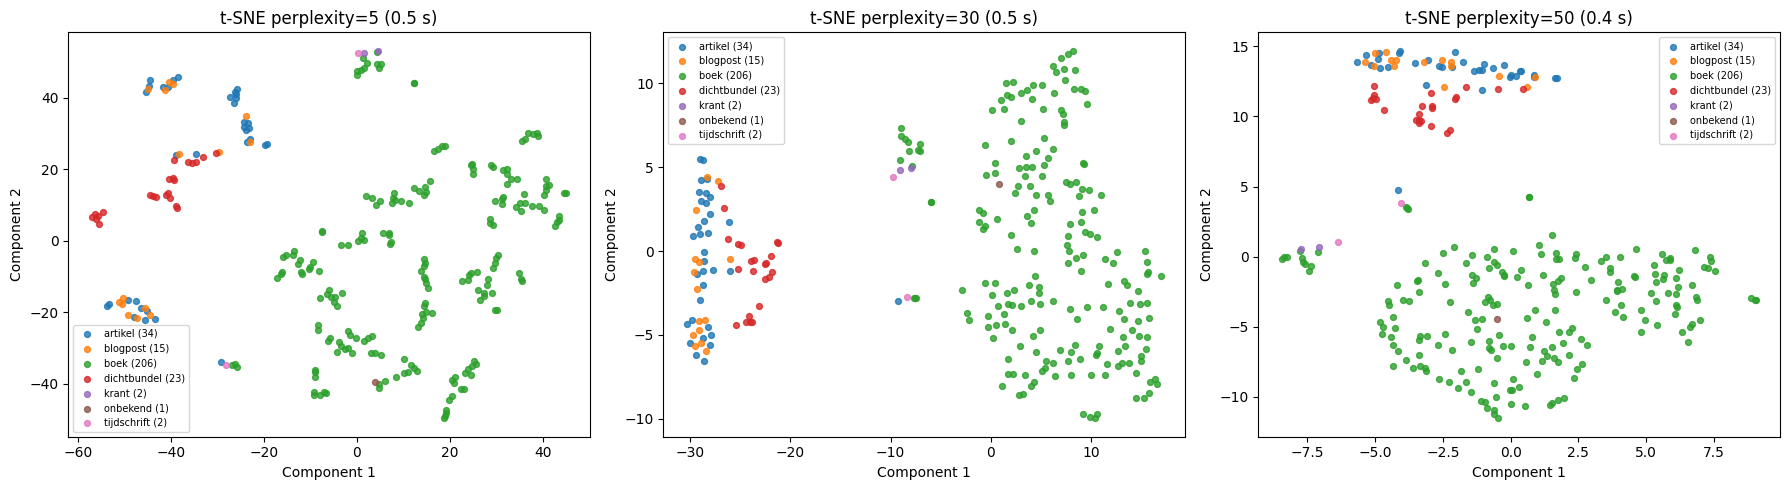

In [11]:
perplexities = [5, 30, 50]
fig, axes = plt.subplots(1, len(perplexities), figsize=(18, 5))
for ax, perplexity in zip(axes, perplexities):
    start = time.time()
    X_tmp = TSNE(n_components=2, perplexity=perplexity, random_state=42).fit_transform(X_scaled)
    plot_projectie(ax, X_tmp, type_materiaal, f"t-SNE perplexity={perplexity} ({time.time() - start:.1f} s)")
plt.tight_layout()
plt.show()

**Wat verandert er bij een andere perplexity?**
- **perplexity = 5**: t-SNE kijkt maar naar een paar buren. De data valt uiteen in veel kleine eilandjes; ook de grote groep boeken wordt in stukjes gehakt. Dat zijn vooral kleine lokale groepjes, geen echte categorieën.
- **perplexity = 30** (standaard): een goede balans. De hoofdgroepen (boeken, korte teksten, dichtbundels) zijn duidelijk te zien.
- **perplexity = 50**: t-SNE kijkt naar meer buren en laat meer de globale structuur zien. De boeken worden één ronde wolk en de korte teksten één band, maar de dichtbundels gaan meer tussen de artikelen zitten.
- De rekentijd blijft bij deze kleine dataset (283 rijen) ongeveer gelijk: minder dan een halve seconde.

### 4.3 UMAP – n_neighbors en min_dist aanpassen

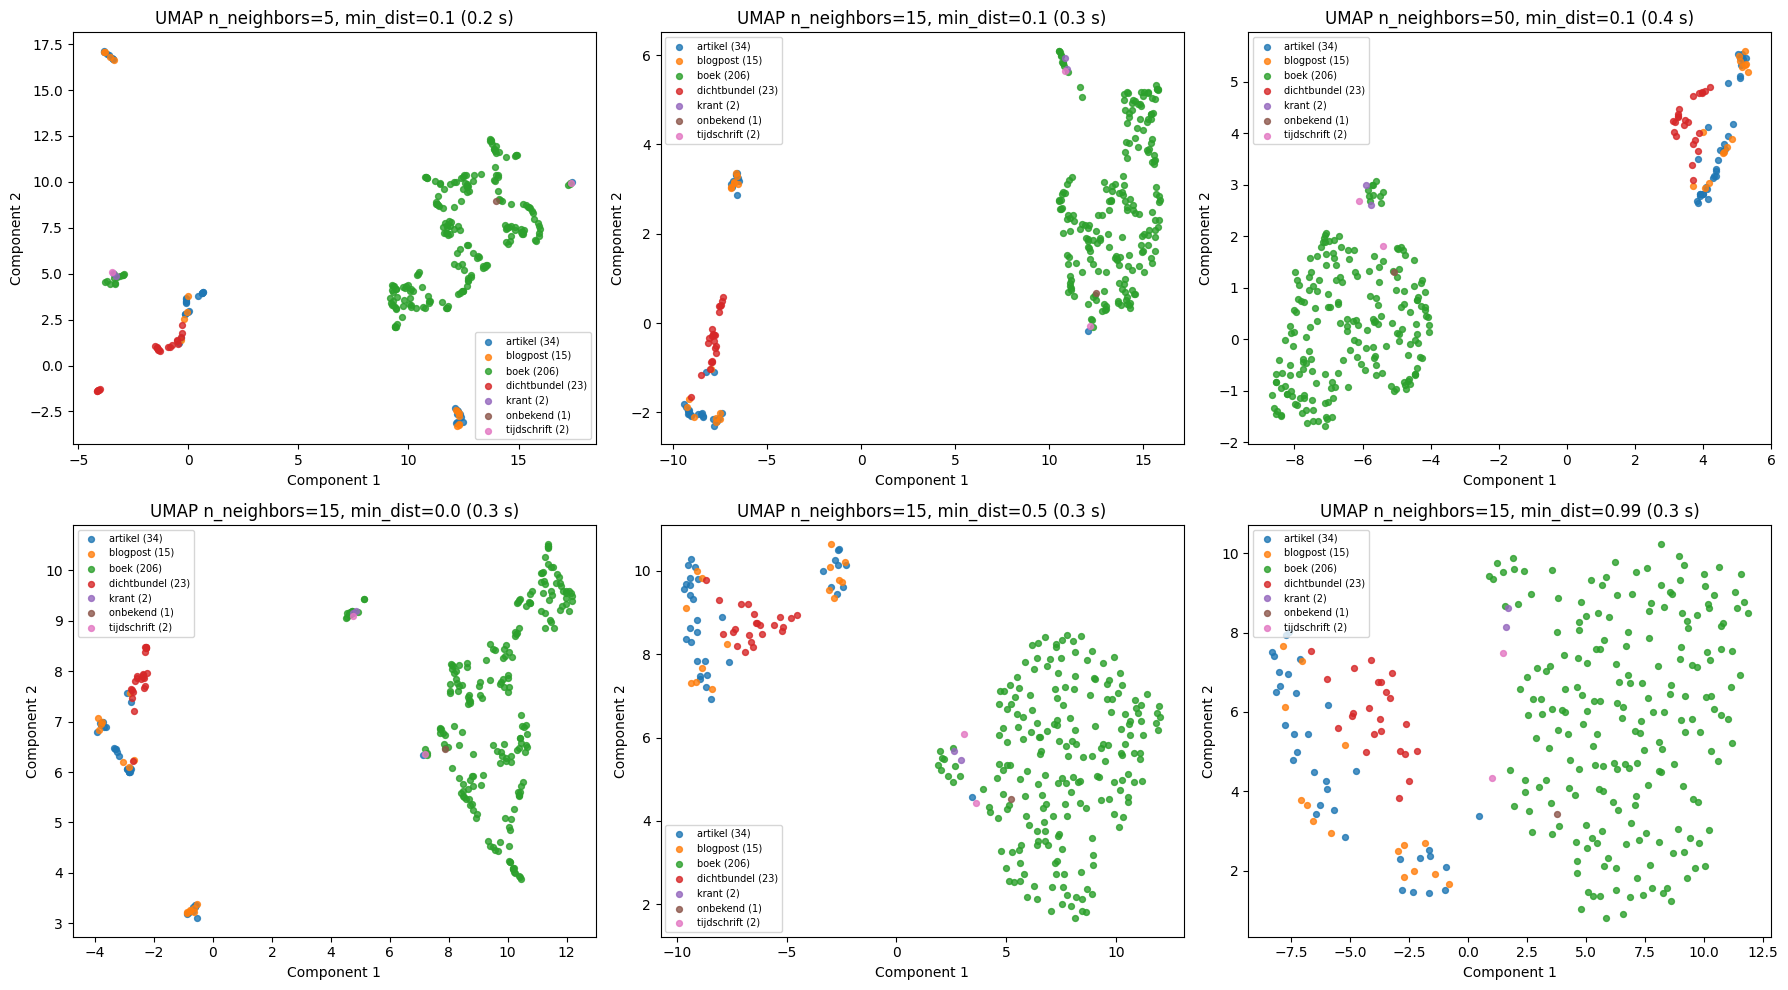

In [12]:
instellingen = [(5, 0.1), (15, 0.1), (50, 0.1), (15, 0.0), (15, 0.5), (15, 0.99)]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (n_neighbors, min_dist) in zip(axes.ravel(), instellingen):
    start = time.time()
    X_tmp = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, random_state=42).fit_transform(X_scaled)
    plot_projectie(ax, X_tmp, type_materiaal,
                   f"UMAP n_neighbors={n_neighbors}, min_dist={min_dist} ({time.time() - start:.1f} s)")
plt.tight_layout()
plt.show()

**Wat verandert er bij andere UMAP-instellingen?**
- **n_neighbors = 5**: veel kleine, losse clusters (net als t-SNE met lage perplexity); de focus ligt op heel lokale structuur.
- **n_neighbors = 50**: minder en grotere groepen. Boeken worden één wolk, en artikelen, blogposts en dichtbundels liggen samen in één groep. Dit laat de globale indeling (lang materiaal vs. korte teksten) het best zien.
- **min_dist = 0.0**: punten worden zo dicht mogelijk op elkaar gedrukt, dus heel strakke clusters.
- **min_dist = 0.5 / 0.99**: punten worden meer verspreid. De clusters worden "wolken" en de grenzen tussen artikelen en dichtbundels vervagen, maar je ziet beter hoe de punten binnen een groep verdeeld zijn.
- **Snelheid**: de eerste UMAP-run duurde ± 7 seconden doordat `numba` de code compileert; daarna kost elke run maar ± 0,3 seconden. Bij een grotere dataset zou UMAP duidelijk sneller zijn dan t-SNE.

## Stap 5 – Conclusie

| | PCA | t-SNE | UMAP |
|---|---|---|---|
| Type | lineair | niet-lineair | niet-lineair |
| Clusters zichtbaar | matig (overlap) | goed | zeer goed |
| Assen/afstanden uitlegbaar | ja (loadings, variantie) | nee | beperkt |
| Snelheid | zeer snel | snel bij kleine data, traag bij grote data | snel (na eerste compilatie) |
| Gevoelig voor parameters | nauwelijks | perplexity | n_neighbors, min_dist |

**Welke techniek past het best bij deze dataset?**
Voor de leescatalogus past **UMAP** het best. Het laat het duidelijkst zien dat de numerieke features het leesmateriaal in drie groepen verdelen: **boeken**, **korte teksten** (artikelen en blogposts) en **dichtbundels**. Ook blijft er met `n_neighbors` en `min_dist` te kiezen tussen een lokaal of een meer globaal beeld.

**PCA** blijft wel nuttig als aanvulling: het is snel, deterministisch, en laat met de loadings zien *waarom* materialen verschillen (PC1 = lengte vs. complexiteit van de tekst). Met 3 componenten blijft bijna 80% van de informatie behouden, wat handig is als voorbewerking voor een model.

Belangrijk inzicht: het **taalniveau** (2F/3F) is met deze features niet te scheiden. Voor een recommender op niveau zijn dus andere features nodig, bijvoorbeeld tekstfeatures uit de omschrijving.

## Reflectievraag

Als ik maar één techniek mocht gebruiken, zou ik **UMAP** kiezen.

In de eindopdracht wil ik leesmateriaal aanbevelen dat past bij een student. Met UMAP kan ik:
- **verkennen** welke groepen leesmateriaal er natuurlijk in de data zitten (zoals boeken vs. korte teksten), en controleren of die groepen logisch zijn;
- **vergelijkbaar materiaal** vinden: titels die in de UMAP-ruimte dicht bij elkaar liggen, lijken qua lengte en leesbaarheid op elkaar, en zijn dus goede kandidaten om samen aan te bevelen;
- dit later ook toepassen op **nieuwe titels** (met `umap_model.transform`), wat bij t-SNE niet kan.

Wel zou ik de UMAP-plot niet te letterlijk lezen: de afstanden tussen clusters zeggen weinig, en de uitkomst hangt af van de instellingen. Daarom zou ik altijd met een paar verschillende waarden voor `n_neighbors` controleren of de clusters stabiel blijven.